In [8]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
DATASET_DIR = "/content/traffic_sign_dataset/traffic_sign"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("TensorFlow:", tf.__version__)
print("Training directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)
print("GPU:", tf.config.list_physical_devices("GPU"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
Training directory: /content/traffic_sign_dataset/traffic_sign/train
Test directory: /content/traffic_sign_dataset/traffic_sign/test
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Traffic_Sign_Project/traffic_sign.zip"
EXTRACT_ROOT = "/content/traffic_sign_dataset"

assert os.path.exists(ZIP_PATH), f"ZIP not found: {ZIP_PATH}"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_ROOT)

# Locate the actual train and test folders
for root, dirs, files in os.walk(EXTRACT_ROOT):
    if "train" in dirs and "test" in dirs:
        TRAIN_DIR = os.path.join(root, "train")
        TEST_DIR = os.path.join(root, "test")
        break
else:
    raise FileNotFoundError(
        "Could not find train and test folders after extraction."
    )

print("Train folder exists:", os.path.exists(TRAIN_DIR))
print("Test folder exists:", os.path.exists(TEST_DIR))
print("Train class folders:", len(os.listdir(TRAIN_DIR)))
print("Test class folders:", len(os.listdir(TEST_DIR)))
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

Train folder exists: True
Test folder exists: True
Train class folders: 85
Test class folders: 85
TRAIN_DIR: /content/traffic_sign_dataset/traffic_sign/train
TEST_DIR: /content/traffic_sign_dataset/traffic_sign/test


## Preparing Dataset

In [16]:
from pathlib import Path
import random
import shutil

TRAIN_DIR = Path(TRAIN_DIR)
VALIDATION_DIR = Path("/content/traffic_sign_dataset/validation")

print("Training folder exists:", TRAIN_DIR.exists())
print("Training class folders:", len([
    p for p in TRAIN_DIR.iterdir() if p.is_dir()
]))

# Recreate an empty validation folder
if VALIDATION_DIR.exists():
    shutil.rmtree(VALIDATION_DIR)

VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

print("Validation folder ready:", VALIDATION_DIR.exists())

Training folder exists: True
Training class folders: 85
Validation folder ready: True


In [17]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
random.seed(42)

train_counts = {}
val_counts = {}

for class_folder in sorted(TRAIN_DIR.iterdir()):
    if not class_folder.is_dir():
        continue

    images = [
        p for p in class_folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]

    if len(images) < 2:
        print(f"Skipping split: {class_folder.name} has fewer than 2 images.")
        continue

    random.shuffle(images)

    val_count = min(
        max(1, round(len(images) * 0.20)),
        len(images) - 1
    )

    val_class_dir = VALIDATION_DIR / class_folder.name
    val_class_dir.mkdir(parents=True, exist_ok=True)

    for image_path in images[:val_count]:
        shutil.copy2(image_path, val_class_dir / image_path.name)

    train_counts[class_folder.name] = len(images) - val_count
    val_counts[class_folder.name] = val_count

train_classes = {
    p.name for p in TRAIN_DIR.iterdir() if p.is_dir()
}
val_classes = {
    p.name for p in VALIDATION_DIR.iterdir() if p.is_dir()
}

print("\nTraining classes:", len(train_classes))
print("Validation classes:", len(val_classes))
print("Training images retained:", sum(train_counts.values()))
print("Validation images:", sum(val_counts.values()))
print("Missing validation classes:", sorted(train_classes - val_classes))

assert train_classes == val_classes, "Some classes are missing from validation!"
assert len(train_classes) == 85

print("SUCCESS: All 85 classes are present in both folders.")


Training classes: 85
Validation classes: 85
Training images retained: 3551
Validation images: 887
Missing validation classes: []
SUCCESS: All 85 classes are present in both folders.


# MobileNetV2

In [18]:
import tensorflow as tf
import numpy as np

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    VALIDATION_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load the original test data
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Verify class order is identical
CLASS_NAMES = train_ds.class_names

assert CLASS_NAMES == val_ds.class_names
assert CLASS_NAMES == test_ds.class_names
assert len(CLASS_NAMES) == 85

print("\nNumber of classes:", len(CLASS_NAMES))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("SUCCESS: Class names and class order match.")

Found 4438 files belonging to 85 classes.
Found 887 files belonging to 85 classes.
Found 1288 files belonging to 85 classes.

Number of classes: 85
Training batches: 139
Validation batches: 28
Test batches: 41
SUCCESS: Class names and class order match.


In [19]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_images(images, labels):
    images = preprocess_input(tf.cast(images, tf.float32))
    return images, labels

train_ds = train_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

# Check one batch
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel value range: -1.0 to 1.0


In [20]:
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = 85

# Load the pretrained MobileNetV2 feature extractor
base_model = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Add a custom classification head
inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 85)             │       108,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,366,869 (9.03 MB)

 Trainable params: 108,885 (425.33 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [22]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath="/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Model compiled successfully.")
print("Total parameters:", model.count_params())
print(
    "Trainable parameters:",
    sum(tf.size(v).numpy() for v in model.trainable_variables)
)
print("Callbacks configured:", len(callbacks))

Model compiled successfully.
Total parameters: 2366869
Trainable parameters: 108885
Callbacks configured: 3


In [23]:
EPOCHS = 50

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - accuracy: 0.2909 - loss: 3.0916
Epoch 1: val_loss improved from None to 0.99661, saving model to /content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 85s 484ms/step - accuracy: 0.4511 - loss: 2.1987 - val_accuracy: 0.7204 - val_loss: 0.9966 - learning_rate: 0.0010
Epoch 2/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.7106 - loss: 0.9752
Epoch 2: val_loss improved from 0.99661 to 0.59515, saving model to /content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 48s 348ms/step - accuracy: 0.7307 - loss: 0.9266 - val_accuracy: 0.8365 - val_loss: 0.5951 - learning_rate: 0.0010
Epoch 3/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 0

50 min

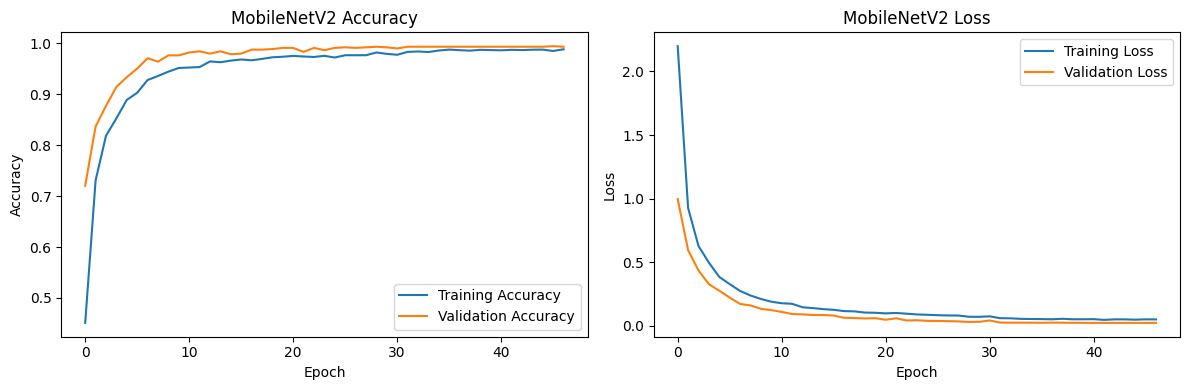

Epochs completed: 47
Best epoch: 42
Best validation accuracy: 0.9944
Lowest validation loss: 0.0231


In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

best_epoch = min(
    range(len(history.history["val_loss"])),
    key=lambda i: history.history["val_loss"][i]
) + 1

print("Epochs completed:", len(history.history["loss"]))
print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"Lowest validation loss: {min(history.history['val_loss']):.4f}")

In [25]:
import tensorflow as tf
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras"

# Load the best checkpoint
best_model = tf.keras.models.load_model(MODEL_PATH)

# Evaluate on the untouched test dataset
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 13s 163ms/step - accuracy: 0.8719 - loss: 0.7297

Test Loss: 0.7297
Test Accuracy: 87.19%


41/41 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step
Accuracy: 0.8719
Macro Precision: 0.706
Macro Recall: 0.701
Macro F1-score: 0.687
Weighted F1-score: 0.8641

Classification Report:

                                 precision    recall  f1-score   support

   ALL_MOTOR_VEHICLE_PROHIBITED     0.6000    0.6000    0.6000         5
                AXLE_LOAD_LIMIT     1.0000    0.4000    0.5714         5
                  BARRIER_AHEAD     0.0000    0.0000    0.0000         2
BULLOCK_AND_HANDCART_PROHIBITED     1.0000    1.0000    1.0000         2
             BULLOCK_PROHIBITED     1.0000    0.4000    0.5714         5
                         CATTLE     0.6250    0.9091    0.7407        11
               COMPULSARY_AHEAD     0.7143    1.0000    0.8333        10
  COMPULSARY_AHEAD_OR_TURN_LEFT     0.0000    0.0000    0.0000         4
 COMPULSARY_AHEAD_OR_TURN_RIGHT     0.4286    0.2500    0.3158        12
         COMPULSARY_CYCLE_TRACK     1.0000    1.0000    1.0000         4
           COMPULSARY

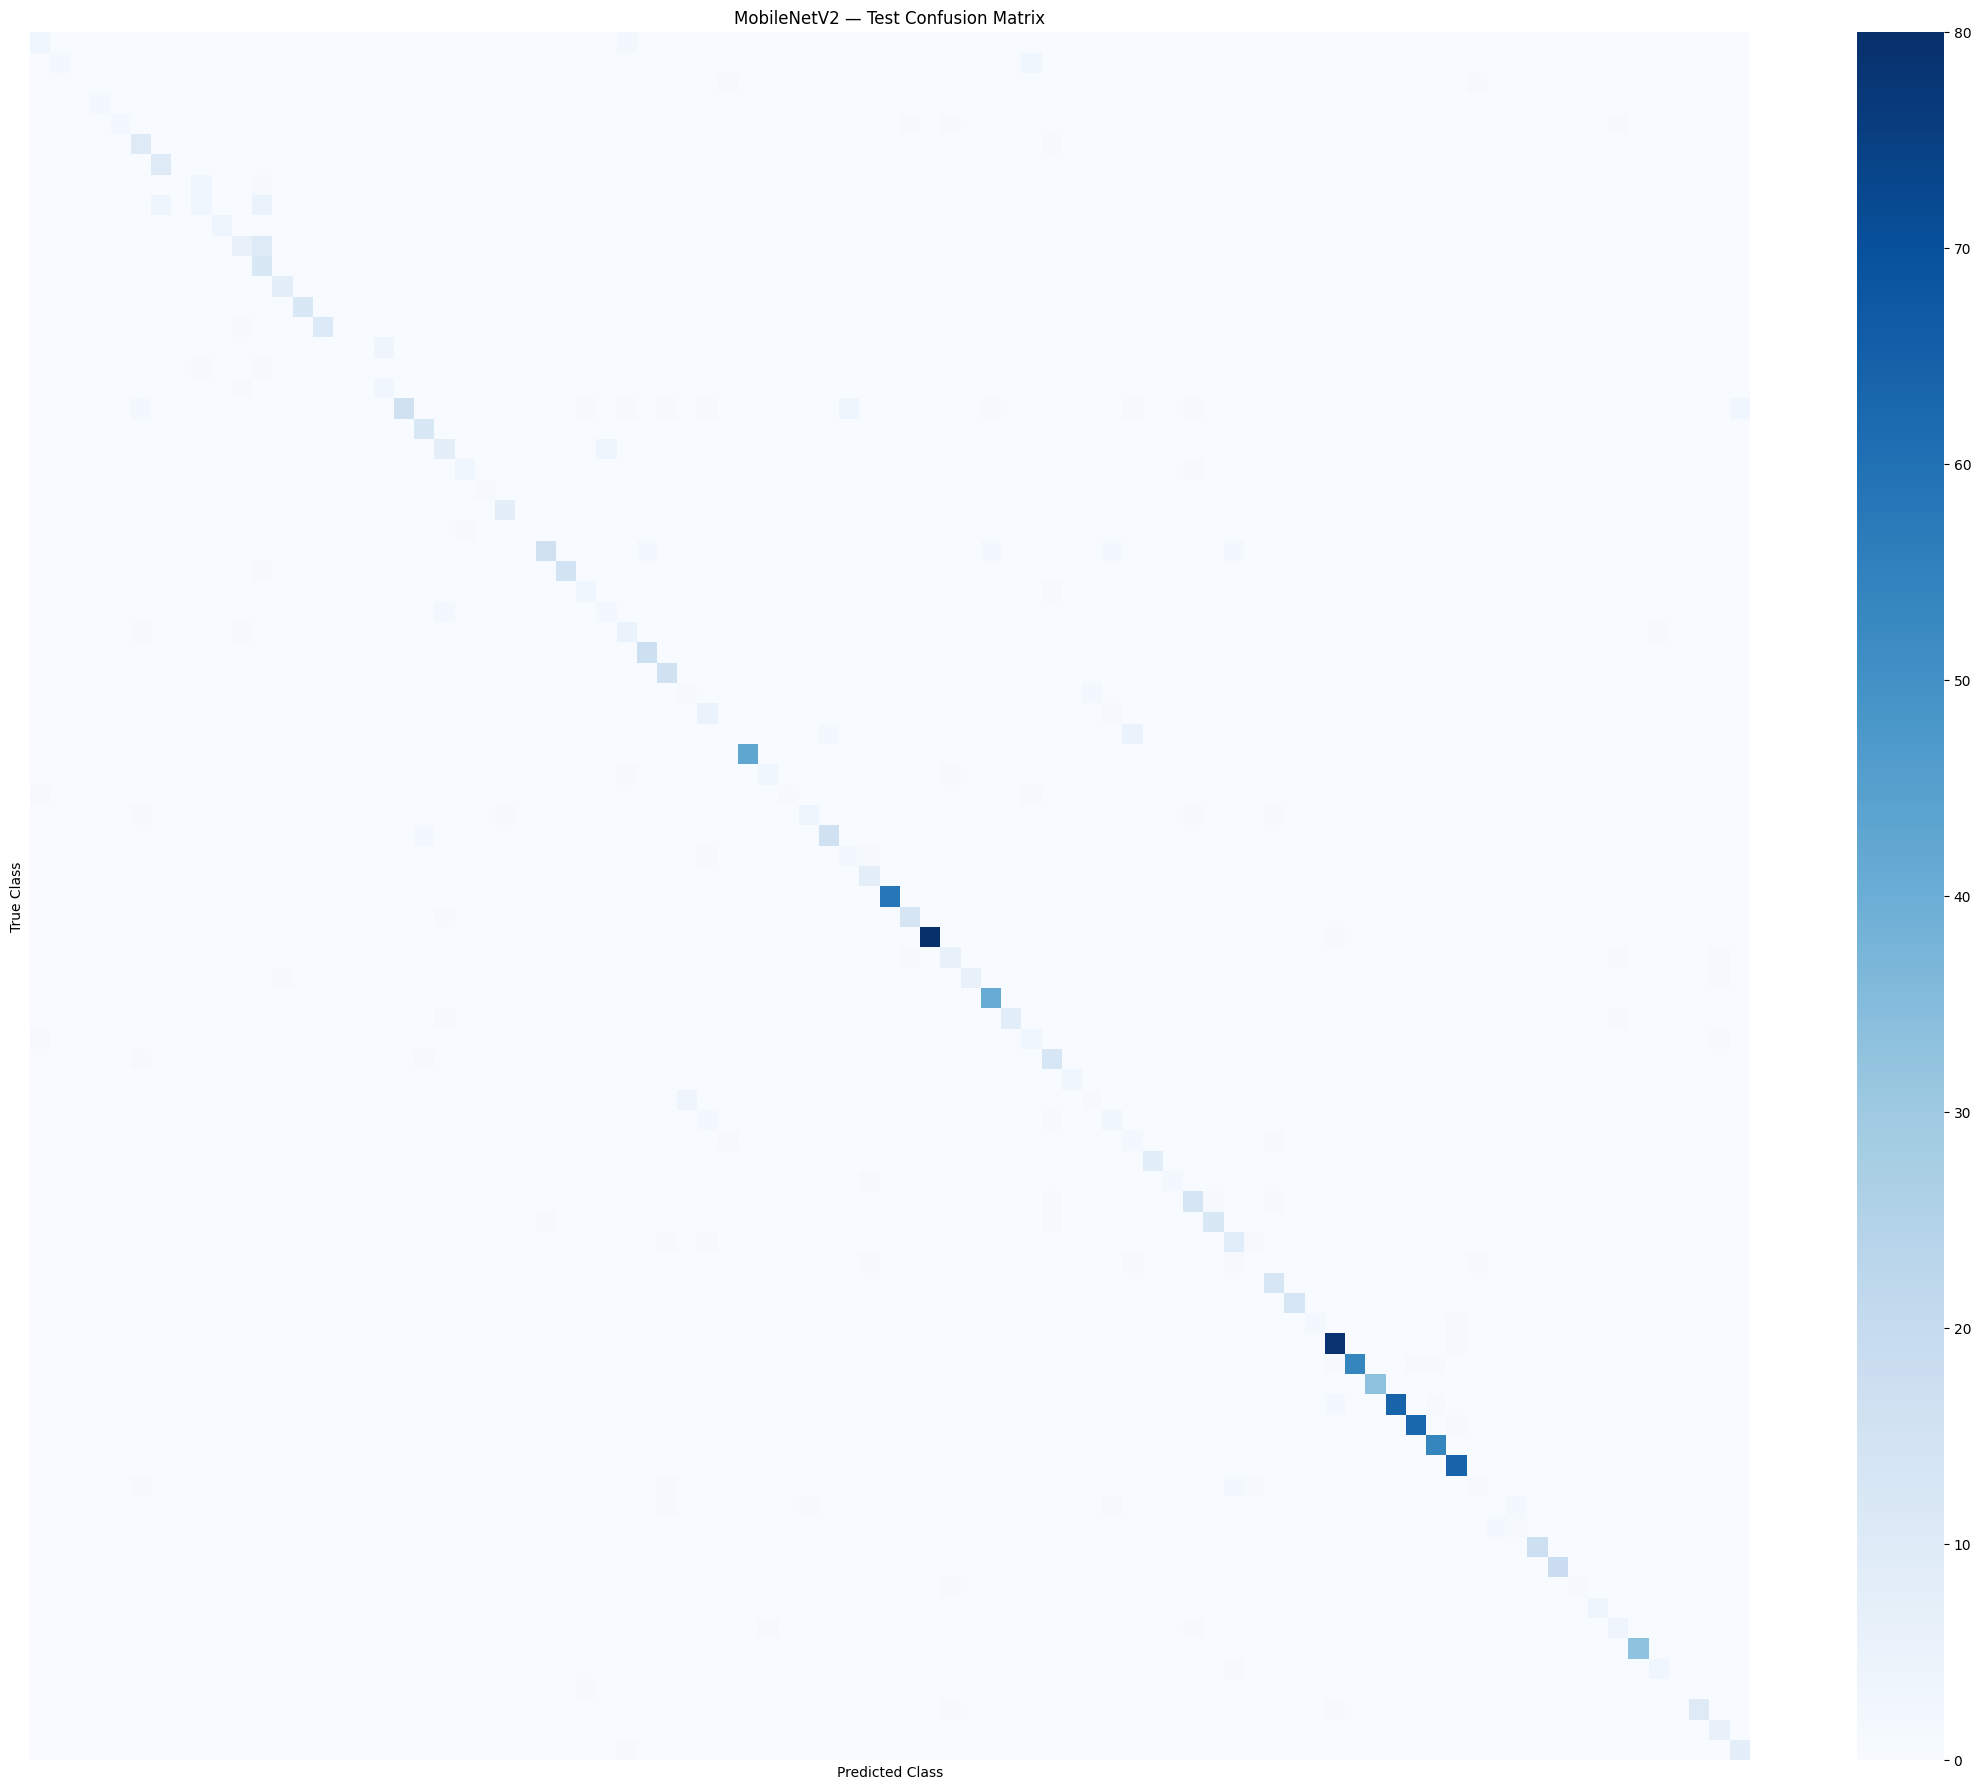

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict probabilities for the test set
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# True labels in the same order as test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Overall metrics
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro Precision:", round(
    precision_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Macro F1-score:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Weighted F1-score:", round(
    f1_score(y_true, y_pred, average="weighted", zero_division=0), 4
))

# Per-class metrics
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES))
)

plt.figure(figsize=(22, 18))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("MobileNetV2 — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

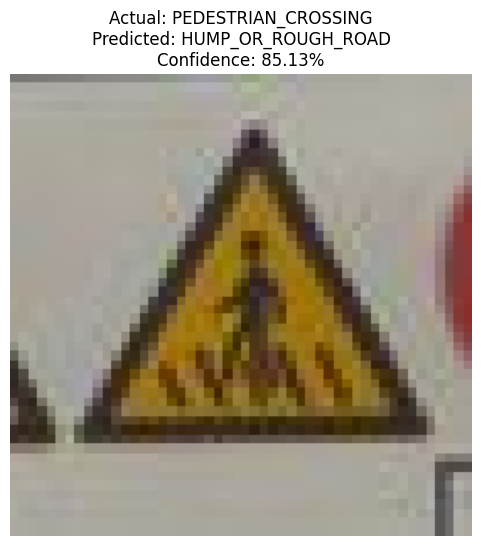

Image: 47092.jpg
Actual class: PEDESTRIAN_CROSSING
Predicted class: HUMP_OR_ROUGH_ROAD
Confidence: 85.13%
Correct prediction: False
Top 3 predictions:
HUMP_OR_ROUGH_ROAD: 85.13%
CYCLE_CROSSING: 9.59%
GAP_IN_MEDIAN: 5.11%


In [43]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

# Use the best trained model
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras"
)

# Find all test images
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in Path(TEST_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

# Choose a random image
image_path = random.choice(image_paths)

# Load and preprocess
img = tf.keras.utils.load_img(
    image_path, target_size=(224, 224)
)
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    img_array
)

# Predict
probabilities = best_model.predict(
    np.expand_dims(img_array, axis=0), verbose=0
)[0]

predicted_idx = int(np.argmax(probabilities))
predicted_class = CLASS_NAMES[predicted_idx]
confidence = float(probabilities[predicted_idx]) * 100
actual_class = image_path.parent.name

# Display image and result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Image:", image_path.name)
print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")
print("Correct prediction:", actual_class == predicted_class)

top_3 = np.argsort(probabilities)[-3:][::-1]

print("Top 3 predictions:")
for idx in top_3:
    print(f"{CLASS_NAMES[idx]}: {probabilities[idx] * 100:.2f}%")

In [39]:
import tensorflow as tf

best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras"
)

val_loss, val_accuracy = best_model.evaluate(val_ds, verbose=1)
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print("\n--- Performance comparison ---")
print(f"Validation loss:     {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")
print(f"Test loss:           {test_loss:.4f}")
print(f"Test accuracy:       {test_accuracy * 100:.2f}%")
print(f"Accuracy gap:        {(val_accuracy - test_accuracy) * 100:.2f} percentage points")

28/28 ━━━━━━━━━━━━━━━━━━━━ 15s 245ms/step - accuracy: 0.9932 - loss: 0.0231
41/41 ━━━━━━━━━━━━━━━━━━━━ 7s 162ms/step - accuracy: 0.8719 - loss: 0.7297

--- Performance comparison ---
Validation loss:     0.0231
Validation accuracy: 99.32%
Test loss:           0.7297
Test accuracy:       87.19%
Accuracy gap:        12.13 percentage points


In [44]:
import tensorflow as tf
from tensorflow import keras

# Load your best trained model
fine_tune_model = keras.models.load_model(
    "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras"
)

# Get the MobileNetV2 backbone
base_model = fine_tune_model.get_layer("mobilenetv2_1.00_224")

# Unfreeze the backbone
base_model.trainable = True

# Freeze most layers; fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Total backbone layers:", len(base_model.layers))
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model.layers)
)
print(
    "Total trainable parameters:",
    sum(
        tf.size(v).numpy()
        for v in fine_tune_model.trainable_variables
    )
)

Total backbone layers: 154
Trainable backbone layers: 19
Total trainable parameters: 1619605


In [45]:
fine_tune_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_finetuned_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fine-tuning model compiled successfully.")
print("Learning rate: 0.00001")
print("Callbacks configured:", len(fine_tune_callbacks))

Fine-tuning model compiled successfully.
Learning rate: 0.00001
Callbacks configured: 3


In [46]:
FINE_TUNE_EPOCHS = 15

fine_tune_history = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks,
    verbose=1
)

Epoch 1/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.9863 - loss: 0.0563
Epoch 1: val_loss improved from None to 0.02037, saving model to /content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_finetuned_best.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 80s 477ms/step - accuracy: 0.9836 - loss: 0.0594 - val_accuracy: 0.9932 - val_loss: 0.0204 - learning_rate: 1.0000e-05
Epoch 2/15
138/139 ━━━━━━━━━━━━━━━━━━━━ 0s 273ms/step - accuracy: 0.9840 - loss: 0.0498
Epoch 2: val_loss did not improve from 0.02037
139/139 ━━━━━━━━━━━━━━━━━━━━ 47s 338ms/step - accuracy: 0.9840 - loss: 0.0481 - val_accuracy: 0.9932 - val_loss: 0.0211 - learning_rate: 1.0000e-05
Epoch 3/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - accuracy: 0.9885 - loss: 0.0364
Epoch 3: val_loss did not improve from 0.02037

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
13

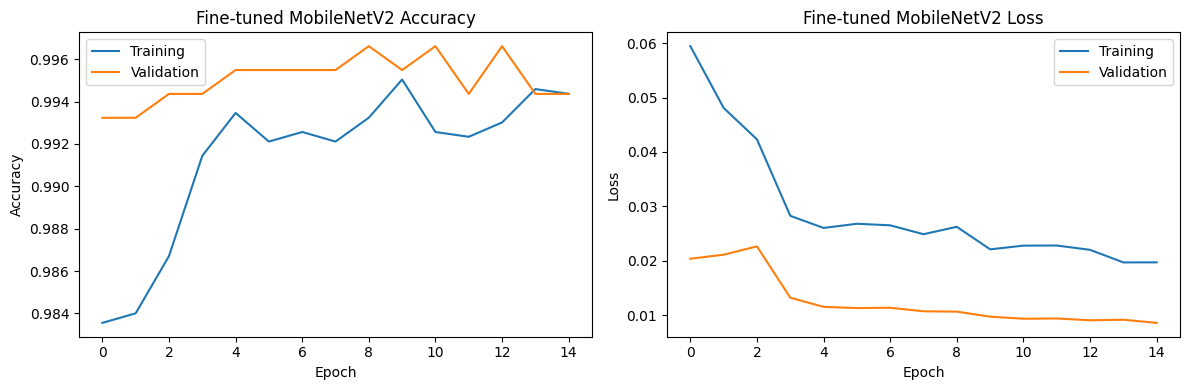

Epochs completed: 15
Best epoch: 15
Best validation accuracy: 0.9966
Lowest validation loss: 0.0086


In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(fine_tune_history.history["accuracy"], label="Training")
plt.plot(fine_tune_history.history["val_accuracy"], label="Validation")
plt.title("Fine-tuned MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fine_tune_history.history["loss"], label="Training")
plt.plot(fine_tune_history.history["val_loss"], label="Validation")
plt.title("Fine-tuned MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

best_epoch = min(
    range(len(fine_tune_history.history["val_loss"])),
    key=lambda i: fine_tune_history.history["val_loss"][i]
)

print("Epochs completed:", len(fine_tune_history.history["loss"]))
print("Best epoch:", best_epoch + 1)
print(f"Best validation accuracy: {max(fine_tune_history.history['val_accuracy']):.4f}")
print(f"Lowest validation loss: {min(fine_tune_history.history['val_loss']):.4f}")

In [49]:
import tensorflow as tf

fine_tuned_best = tf.keras.models.load_model(
    "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_finetuned_best.keras"
)

test_loss_ft, test_accuracy_ft = fine_tuned_best.evaluate(
    test_ds,
    verbose=1
)

print(f"\nFine-tuned Test Loss: {test_loss_ft:.4f}")
print(f"Fine-tuned Test Accuracy: {test_accuracy_ft * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.8797 - loss: 0.7791

Fine-tuned Test Loss: 0.7791
Fine-tuned Test Accuracy: 87.97%


In [50]:
original_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_best.keras"
)

original_loss, original_accuracy = original_model.evaluate(
    test_ds,
    verbose=0
)

print("Model comparison")
print("-" * 40)
print(f"Original MobileNetV2:   {original_accuracy * 100:.2f}%")
print(f"Fine-tuned MobileNetV2: {test_accuracy_ft * 100:.2f}%")
print(
    f"Accuracy change:        "
    f"{(test_accuracy_ft - original_accuracy) * 100:+.2f} percentage points"
)

Model comparison
----------------------------------------
Original MobileNetV2:   87.19%
Fine-tuned MobileNetV2: 87.97%
Accuracy change:        +0.78 percentage points


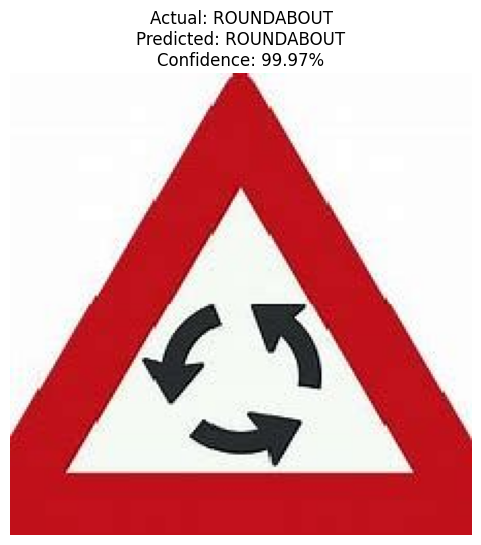

Image: 57060.jpg
Actual class: ROUNDABOUT
Predicted class: ROUNDABOUT
Confidence: 99.97%
Correct prediction: True
Top 3 predictions:
ROUNDABOUT: 99.97%
SCHOOL_AHEAD: 0.01%
RIGHT_HAIR_PIN_BEND: 0.00%


In [53]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

# Use the best trained model
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Traffic_Sign_Project/model/mobilenetv2_finetuned_best.keras"
)

# Find all test images
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in Path(TEST_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

# Choose a random image
image_path = random.choice(image_paths)

# Load and preprocess
img = tf.keras.utils.load_img(
    image_path, target_size=(224, 224)
)
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    img_array
)

# Predict
probabilities = best_model.predict(
    np.expand_dims(img_array, axis=0), verbose=0
)[0]

predicted_idx = int(np.argmax(probabilities))
predicted_class = CLASS_NAMES[predicted_idx]
confidence = float(probabilities[predicted_idx]) * 100
actual_class = image_path.parent.name

# Display image and result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Image:", image_path.name)
print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")
print("Correct prediction:", actual_class == predicted_class)

top_3 = np.argsort(probabilities)[-3:][::-1]

print("Top 3 predictions:")
for idx in top_3:
    print(f"{CLASS_NAMES[idx]}: {probabilities[idx] * 100:.2f}%")

In [54]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true_ft = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob_ft = fine_tuned_best.predict(test_ds, verbose=1)
y_pred_ft = np.argmax(y_prob_ft, axis=1)

print(f"Accuracy: {accuracy_score(y_true_ft, y_pred_ft):.4f}")
print(f"Macro Precision: {precision_score(y_true_ft, y_pred_ft, average='macro', zero_division=0):.4f}")
print(f"Macro Recall: {recall_score(y_true_ft, y_pred_ft, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score: {f1_score(y_true_ft, y_pred_ft, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-score: {f1_score(y_true_ft, y_pred_ft, average='weighted', zero_division=0):.4f}")

41/41 ━━━━━━━━━━━━━━━━━━━━ 12s 121ms/step
Accuracy: 0.8797
Macro Precision: 0.7104
Macro Recall: 0.7050
Macro F1-score: 0.6934
Weighted F1-score: 0.8717


In [56]:
import os
import json
import tensorflow as tf
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR, "mobilenetv2_finetuned.keras"
)
CLASS_PATH = os.path.join(
    MODEL_DIR, "class_names_mobilenetv2.json"
)

# Save the fine-tuned model
fine_tuned_best.save(MODEL_PATH)

# Save class names in the exact output order
with open(CLASS_PATH, "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, indent=4, ensure_ascii=False)

print("Model saved:", os.path.exists(MODEL_PATH))
print("Class names saved:", os.path.exists(CLASS_PATH))
print("Number of classes:", len(CLASS_NAMES))
print("Model size (MB):", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved: True
Class names saved: True
Number of classes: 85
Model size (MB): 21.95
